# Paper 21: Halal cash while the switch is off

v2 sits in **broker cash at 0%** on the 352 sessions the SPY 200-day switch is off. This paper does **not** put a defensive stock list back on (paper 09 already killed that). It credits a **Shariah money-market / sukuk yield** on idle cash and leaves the FCF list unchanged.

Change only `accounting.cash_yield`. Overlay, brain, construction, and screens stay on v2. Try 2%, 4%, and 5%. There is no tradable sukuk proxy on this snapshot, so the yield is a constant — the board-rate case, not a ticker.

Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** cash-2, cash-4, cash-5.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-21-halal-cash", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="21-halal-cash",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545


        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One yield at a time


In [2]:
cash_2 = run_book("fcf-sma-v2-baseline", rd, paper="21-halal-cash", id="cash-2", accounting={"cash_yield": 0.02})
cash_4 = run_book("fcf-sma-v2-baseline", rd, paper="21-halal-cash", id="cash-4", accounting={"cash_yield": 0.04})
cash_5 = run_book("fcf-sma-v2-baseline", rd, paper="21-halal-cash", id="cash-5", accounting={"cash_yield": 0.05})
trials = [cash_2, cash_4, cash_5]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date', 'cash yield': 'none'}
cash-2 3a515ed24f06
  {'book': 'cash-2', 'hash': '3a515ed24f06', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'sector floors': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp cha

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
cash-2,1.1176,0.1179,0.1463,-0.2355,0.5007,0.7012,0.8893,4.1620,0.0560,0.0560,0.8032,36.0000,3a515ed24f06
cash-4,1.1743,0.1223,0.1463,-0.2231,0.5483,0.7282,0.8760,4.1571,0.0560,0.0560,0.8032,36.0000,b40de0d0b7e6
cash-5,1.2020,0.1245,0.1463,-0.2167,0.5742,0.7411,0.8915,4.1587,0.0560,0.0560,0.8032,36.0000,8269cb1db7fb
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


cash-2 keep pass
cash-4 keep pass
cash-5 keep pass


## Did the yield bind?

`compare` only sees NAV. Count cash-yield credits, near-cash sessions, and whether exposure still matches v2 (the equity list must not change).


In [5]:
import pandas as pd

rows = []
for book in [base, *trials]:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    flows = book.cashflows
    y = flows[flows["type"] == "cash_yield"] if flows is not None and not flows.empty else pd.DataFrame(columns=["amount"])
    rows.append({
        "book": book.spec.id,
        "yield_credits": int(len(y)),
        "yield_dollars": float(y["amount"].sum()) if not y.empty else 0.0,
        "near_cash_days": int((nav["invested"] / nav["nav"] < 0.05).sum()),
        "avg_exposure": float(nav["exposure"].mean()),
        "switches": int((nav["exposure"].astype(float).diff().fillna(0) != 0).sum()),
    })
pd.DataFrame(rows).set_index("book")


,yield_credits,yield_dollars,near_cash_days,avg_exposure,switches
book,,,,,
v2,0,0.0000,333,0.8032,36
cash-2,1692,"30,014.5463",333,0.8032,36
cash-4,1692,"60,278.0824",333,0.8032,36
cash-5,1692,"75,510.8492",333,0.8032,36


## Path, not just the scorecard


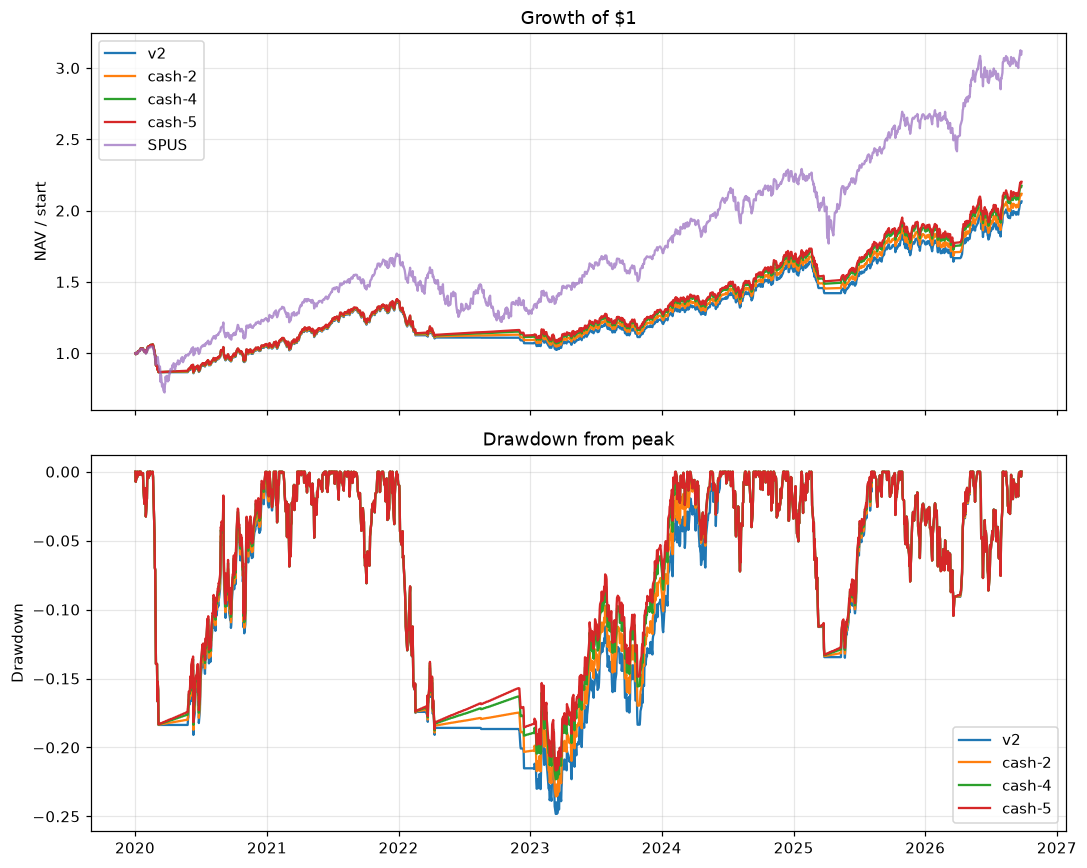

wrote figures/nav-and-drawdown.png


In [6]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)
spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    axes[0].plot(nav.index, nav / nav.iloc[0], label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)
axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()
fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


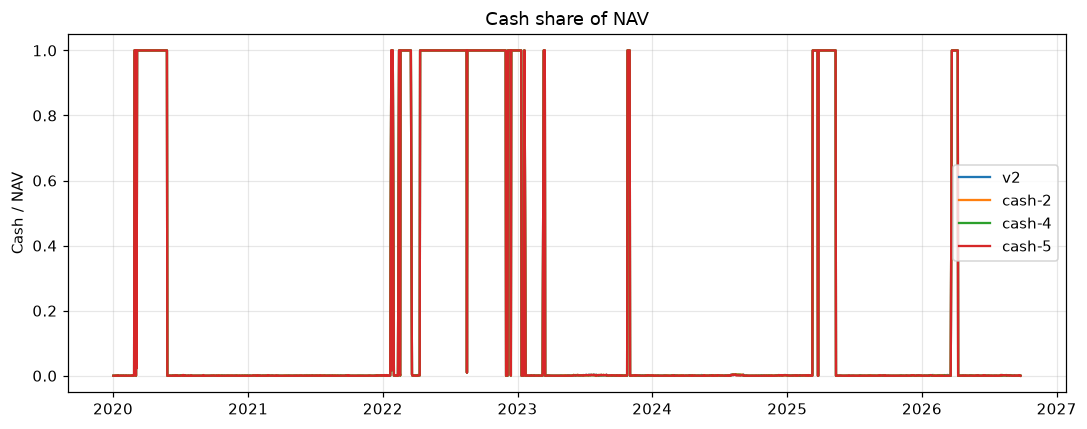

wrote figures/cash-share.png


In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    nav = book.nav.copy()
    nav["date"] = pd.to_datetime(nav["date"])
    ax.plot(nav["date"], nav["cash"] / nav["nav"], label=book.spec.id)
ax.set_title("Cash share of NAV")
ax.set_ylabel("Cash / NAV")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "cash-share.png", dpi=140)
plt.show()
print("wrote", figures / "cash-share.png")


,v2,cash-2,cash-4,cash-5,SPUS
year,,,,,
2020,0.0528,0.0576,0.0624,0.0647,0.2399
2021,0.2831,0.2833,0.2834,0.2834,0.3562
2022,-0.2080,-0.1954,-0.1829,-0.1765,-0.2276
2023,0.1525,0.1540,0.1559,0.1567,0.3420
2024,0.2741,0.2741,0.2744,0.2746,0.2649
2025,0.1250,0.1286,0.1323,0.1340,0.1978
2026,0.1681,0.1687,0.1700,0.1705,0.1802


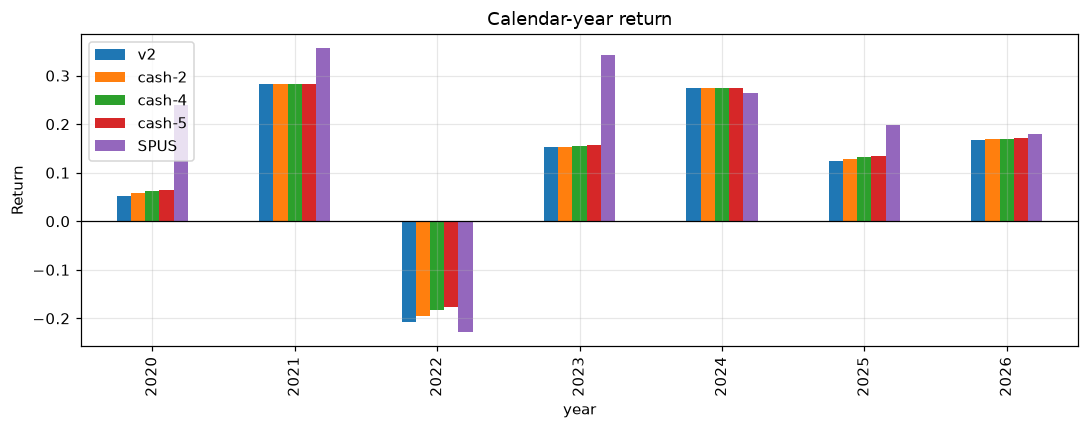

wrote figures/calendar-returns.png


In [8]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Conclusion

**Would we run this?** Yes, as economics. A 4% Halal cash yield on idle NAV lifts Calmar from **0.46 to 0.55** and cuts max drawdown from **−24.8% to −22.3%**, with the same FCF list and the same 36 SPY flips. All three yields pass the kill rules. The live book still needs a **named sukuk / Shariah money-market vehicle** before this is an ops rule. The rate is a constant in this notebook, not a traded ticker.

**What we asked.** v2 earns **0%** on the 333 near-cash sessions the SMA is off. Paper 09 already showed that a defensive *stock* list while SPY is weak still falls ~26%. This paper credits 2% / 4% / 5% a year on leftover cash, every session, and does not change overlay, names, or caps.

**What happened.**

- The yield binds. Same 36 switches, same 0.80 average exposure, same 333 near-cash days. Cash-4 credits about **$60k** on a $1M start (~6% of starting NAV over 2020–26). Cash-2 about $30k; cash-5 about $76k.
- The path gets better without taking equity risk back. v2 +106% / −24.8% / Calmar 0.46. Cash-2: +112% / −23.6% / **0.50**. Cash-4: +117% / −22.3% / **0.55**. Cash-5: +120% / −21.7% / **0.57**. 2022 is the visible help (−19.5% / −18.3% / −17.7% versus v2 −20.8%). 2023 barely moves.
- SPUS Calmar is still 0.60. Productive cash closes part of the gap. It does not replace a better overlay or a better stock list.

**What this means for the fund.** Sitting in 0% cash is a choice, not a law of nature. If the board will accept a short sukuk / Islamic money-market rate around 4%, quote that net path. Do not confuse this with paper 16's partial-50 (that still owns stocks in a crash). Combine later with paper 23 if SPUS becomes the switch; the idle days will still need a yield.

**Live rule.** Keep `cash_yield` off on the scored v2 hash. Promote a 4% (or board-agreed) yield once the vehicle is named. Do not invent a ticker. Do not put a second stock list in the cash sleeve.
